# Bloque 1 Librerias 

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
print("Listo")

Listo


# Bloque 2 Cargar el dataset desde tu computadora

In [19]:
RUTA="datos/mammographic_masses.data"
datos = pd.read_csv(RUTA, header=None, na_values="?")

print("Cantidad de columnas: ", datos.shape[1])

datos = datos.dropna()
X = datos.iloc[:, 1: -1]
y = datos.iloc[:, -1]

print("Caracteristicas: ",X.shape[1])
print("Muestras: ", X.shape[0])

Cantidad de columnas:  6
Caracteristicas:  4
Muestras:  830


# Bloque 3 Separar entrenamiento  y pruebas 

In [20]:
X = datos.iloc[:, 1: -1].to_numpy(float)
y = datos.iloc[:, -1].to_numpy(int)

indices = rng.permutation(len(X))
corte = int(0.8 * len(X))

X_ent = X[indices[:corte]]
X_pru = X[indices[corte:]]

y_ent = y[indices[:corte]]
y_pru = y[indices[corte:]]

print("Entrenamiento: ", len(X_ent))
print("Prueba: ", len(X_pru))
print("Caracteristicas: ", X.shape[1])

Entrenamiento:  664
Prueba:  166
Caracteristicas:  4


# Bloque 4 Normalizar las entradas

In [21]:
minimos = X_ent.min(axis=0)
rangos = X_ent.max(axis=0) - minimos
rangos[rangos == 0] = 1

X_ent = (X_ent - minimos) / rangos
X_pru = (X_pru - minimos) / rangos

# Bloque 5 Definir como se clasifica el cromosoma 

In [22]:
def probabilidad(cromosoma, X):
    z = X @ cromosoma[:-1] + cromosoma[-1]
    z = np.clip(z, -30, 30)
    return 1 / (1 + np.exp(-z))

def clasificar(cromosoma, X):
    return (probabilidad(cromosoma, X) >= 0.5).astype(int)

# Bloque 6 Fitness: F1-score

In [23]:
def fitness(cromosoma, X, y):
    pred = clasificar(cromosoma, X)
    vp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    return 2 * vp / max(2 * vp + fp + fn, 1)

# Bloque 7 Configuracion e inicializacion de poblacion

In [24]:
POBLACION = 100
GENERACIONES = 50
PROB_CRUCE = 0.80
PROB_MUTACION = 0.10

NUMERO_GENES = X_ent.shape[1] + 1

poblacion = rng.uniform(-1, 1, (POBLACION, NUMERO_GENES))

print("Individuos: ", len(poblacion))
print("Genes por individuo: ", NUMERO_GENES)

Individuos:  100
Genes por individuo:  5


# Bloque 8 Evaluacion de la poblacion inicial 

In [25]:
puntos = np.array([fitness(c, X_ent, y_ent) for c in poblacion])

print("F1 de cada individuo: ", np.round(puntos , 3))
print("Mejor F1 inicial: ", round(puntos.max(), 3))

F1 de cada individuo:  [0.    0.757 0.024 0.143 0.655 0.733 0.655 0.661 0.486 0.771 0.801 0.089
 0.771 0.282 0.47  0.675 0.024 0.655 0.569 0.655 0.    0.655 0.522 0.654
 0.    0.655 0.655 0.316 0.748 0.    0.    0.    0.092 0.    0.324 0.655
 0.    0.    0.075 0.126 0.655 0.648 0.063 0.    0.655 0.    0.635 0.653
 0.    0.164 0.521 0.655 0.133 0.419 0.628 0.655 0.655 0.654 0.156 0.793
 0.655 0.    0.123 0.118 0.    0.776 0.655 0.798 0.351 0.089 0.222 0.648
 0.09  0.655 0.006 0.66  0.    0.733 0.    0.621 0.654 0.    0.655 0.
 0.    0.195 0.655 0.655 0.655 0.646 0.654 0.729 0.089 0.098 0.012 0.006
 0.796 0.655 0.314 0.655]
Mejor F1 inicial:  0.801


# Bloque 9 Seleccion de torneo binario

In [ ]:
def torneo(poblacion, puntos):
    a,b = rng.choice(len(poblacion), 2, replace=False)
    ganador = a if puntos[a] >= puntos[b] else b
    return poblacion[ganador].copy()

# Bloque 10 Cruce

In [27]:
def cruce(p1, p2):
    if rng.random() < PROB_CRUCE:
        corte = rng.integers(1, len(p1))
        return np.r_[p1[:corte], p2[corte:]]
    return p1.copy()

# Bloque 11 Mutación

In [28]:
def mutacion(cromosoma):
    for i in range(len(cromosoma)):
        if rng.random() < PROB_MUTACION:
            cromosoma[i] += rng.normal(0, 0.4)
    return np.clip(cromosoma, -5, 5)

# Bloque 12 Formar una nueva generación

In [29]:
def nueva_generacion(poblacion):
    puntos = np.array([fitness(c, X_ent, y_ent) for c in poblacion])
    nuevos = []
    for _ in range(POBLACION):
        p1 = torneo(poblacion, puntos)
        p2 = torneo(poblacion, puntos)
        nuevos.append(mutacion(cruce(p1,p2)))
    return np.array(nuevos)

# Bloque 13 Ejecutar el algoritmo genetico 

In [30]:
mejor_f1 = -1
historial = []
for g in range(GENERACIONES + 1):
    puntos = np.array([fitness(c, X_ent, y_ent) for c in poblacion])
    i = np.argmax(puntos)
    historial.append(puntos[i])
    if puntos[i] > mejor_f1:
        mejor_f1, mejor = puntos[i], poblacion[i].copy()
    if g % 10 == 0 or g == GENERACIONES:
        print(f"Generacion {g}: mejor F1 = {puntos[i]:.3f}")
    if g < GENERACIONES:
        poblacion = nueva_generacion(poblacion)

Generacion 0: mejor F1 = 0.801


Generacion 10: mejor F1 = 0.803
Generacion 20: mejor F1 = 0.808
Generacion 30: mejor F1 = 0.811
Generacion 40: mejor F1 = 0.808
Generacion 50: mejor F1 = 0.809


# Bloque 14 Evaluación final en datos de prueba 

In [31]:
pred = clasificar(mejor,X_pru)
exactitud = np.mean(pred == y_pru)
print("Mejor cromosoma: ", np.round(mejor, 3))
print("Exactitud en prueba: ", round(exactitud, 3))
print("F1 en prueba: ", round(fitness(mejor, X_pru, y_pru), 3))

Mejor cromosoma:  [ 0.597  0.644  0.555  0.464 -1.042]
Exactitud en prueba:  0.819
F1 en prueba:  0.826


# Bloque 15 Clasificar registros del dataset

In [32]:
for i in range(min(10, len(X_pru))):
    proba = probabilidad(mejor, X_pru[i:i+1])[0]
    clase = "Maligno" if proba >= 0.5 else "Benigno"
    real = "Maligno" if y_pru[i] == 1 else "Benigno"
    print(f"Caso {i+1}: real={real}, prediccion={clase}, puntuacion={proba:.2f}")

Caso 1: real=Maligno, prediccion=Maligno, puntuacion=0.67
Caso 2: real=Maligno, prediccion=Maligno, puntuacion=0.68
Caso 3: real=Benigno, prediccion=Benigno, puntuacion=0.43
Caso 4: real=Maligno, prediccion=Maligno, puntuacion=0.68
Caso 5: real=Benigno, prediccion=Benigno, puntuacion=0.38
Caso 6: real=Maligno, prediccion=Maligno, puntuacion=0.54
Caso 7: real=Maligno, prediccion=Maligno, puntuacion=0.63
Caso 8: real=Maligno, prediccion=Maligno, puntuacion=0.66
Caso 9: real=Maligno, prediccion=Maligno, puntuacion=0.61
Caso 10: real=Benigno, prediccion=Benigno, puntuacion=0.36


# Bloque 16 Clasificar un caso nuevo

In [33]:
caso = np.array([[67, 5, 3, 2]], dtype=float)
caso = (caso - minimos) / rangos
p = probabilidad(mejor, caso)[0]
print("Prediccion: ", "Maligno" if p >= 0.5 else "Benigno")
print("Puntuacion del modelo: ", round(p, 3))

Prediccion:  Maligno
Puntuacion del modelo:  0.654


# Bloque 17 Grafica de evolicion del F1-score

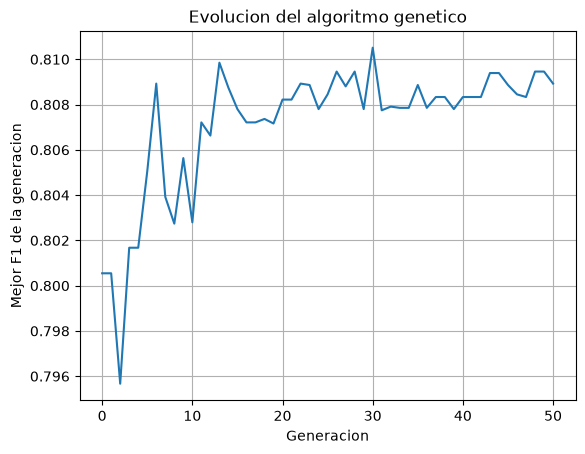

In [ ]:
plt.plot(historial)
plt.xlabel("Generacion")
plt.ylabel("Mejor F1 de la generacion")
plt.title("Evolucion del algoritmo genetico")
plt.grid(True)
plt.show()